In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

data, meta = arff.loadarff("/Users/hari/Downloads/Bankruptcy/bankruptcy-prediction/data/raw/3year.arff")
df = pd.DataFrame(data)
df["class"] = df["class"].str.decode("utf-8").astype(int)

# 1. Class balance — How many companies went bankrupt?
Question: How many companies are healthy, and how many went bankrupt?

Imagine we have 1,000 companies:
- 950 healthy companies (0)
- 50 bankrupt companies (1)
If our model predicts every company as healthy, it gets 95% accuracy — but it fails to identify even one bankrupt company!

Why do we check this first?

To understand whether our data is imbalanced and choose suitable evaluation metrics, such as Recall, F1-score, Precision, and ROC-AUC.

class
0    10008
1      495
Name: count, dtype: int64
class
0    0.9529
1    0.0471
Name: proportion, dtype: float64


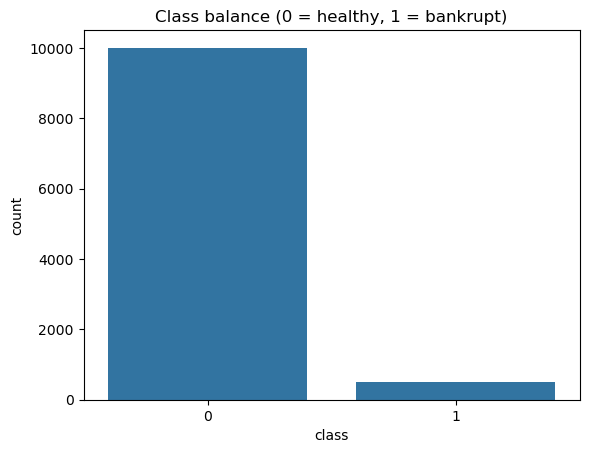

In [22]:

print(df["class"].value_counts())
print(df["class"].value_counts(normalize=True).round(4))
sns.countplot(x="class", data=df)
plt.title("Class balance (0 = healthy, 1 = bankrupt)")
plt.show()

# 2. Missing values

Attr37    45.09
Attr21     7.68
Attr27     6.81
Attr60     5.64
Attr45     5.63
Attr28     2.17
Attr53     2.17
Attr54     2.17
Attr64     2.17
Attr24     2.16
dtype: float64
Columns with any missing: 44 of 65
Rows with any missing: 5618 of 10503


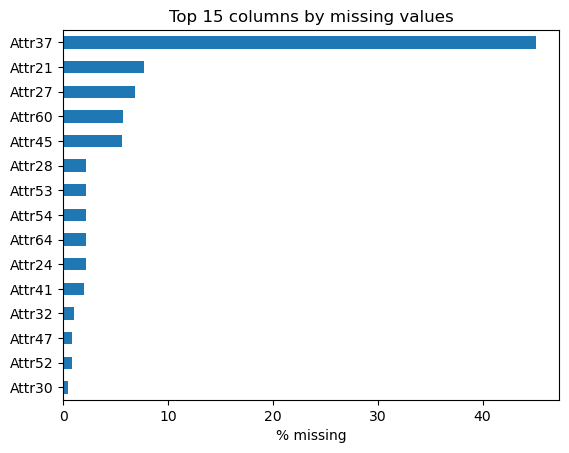

In [23]:

missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print(missing_pct.head(10).round(2))
print("Columns with any missing:", (missing_pct > 0).sum(), "of", df.shape[1])
print("Rows with any missing:", df.isna().any(axis=1).sum(), "of", len(df))

missing_pct.head(15).plot(kind="barh")
plt.xlabel("% missing")
plt.title("Top 15 columns by missing values")
plt.gca().invert_yaxis()
plt.show()

 # 3. Duplicates and data types

In [24]:

print("Duplicate rows:", df.duplicated().sum())
print(df.dtypes.value_counts())


Duplicate rows: 87
float64    64
int64       1
Name: count, dtype: int64


# 4. Scale and outliers: look at the extremes

In [25]:

summary = df.describe().T[["min", "50%", "max"]]
summary["max_over_median"] = summary["max"] / summary["50%"].abs()
print(summary.sort_values("max_over_median", ascending=False).head(10))


                 min        50%          max  max_over_median
class   0.000000e+00   0.000000        1.000              inf
Attr6  -5.081200e+02   0.000000       45.533              inf
Attr41 -6.677300e+02   0.079126   288770.000     3.649496e+06
Attr59 -1.720700e+02   0.002976     7617.300     2.559233e+06
Attr27 -1.901300e+05   1.066900  2723000.000     2.552254e+06
Attr5  -1.190300e+07   1.579300   685440.000     4.340151e+05
Attr45 -7.438500e+04   0.261265   113280.000     4.335828e+05
Attr52 -2.546700e+01   0.212000    84827.000     4.001274e+05
Attr60  0.000000e+00   9.952100  3660200.000     3.677817e+05
Attr32 -9.295600e+03  77.522000  6674200.000     8.609427e+04


# 5. One feature up close

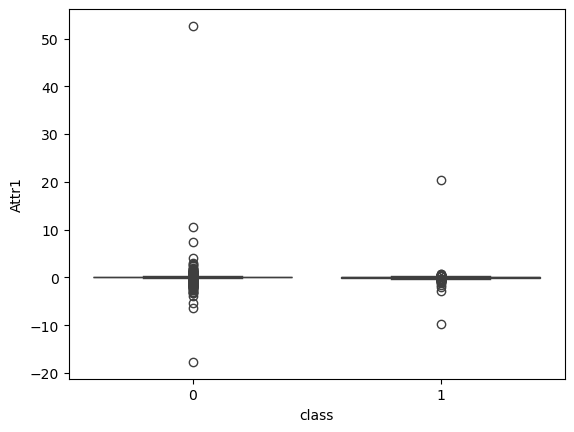

In [26]:

sns.boxplot(x="class", y="Attr1", data=df)  # Attr1 = net profit / total assets
plt.show()